# MACHINE LEARNING SAML-D

# 1. Importação e Configuração

In [ ]:
import time
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from IPython.display import display

# Cria uma cópia não treinada de um estimador
from sklearn.base import clone

# Aplica transformações diferentes às colunas numéricas e categóricas
from sklearn.compose import ColumnTransformer

# Reduz a dimensionalidade dos dados
from sklearn.decomposition import PCA

# Modelos 
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
import sys
!{sys.executable} -m pip install --quiet lightgbm
from lightgbm import LGBMClassifier

# Conecta as etapas de processamento e treinamento em uma única estrutura
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold, StratifiedKFold

from sklearn.impute import SimpleImputer

from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_curve,
)

# warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# CONFIGURAÇÃO
# Caminho do dataset
CAMINHO_CSV = "SAML-D.csv"
# Número de linhas carregadas para teste
NROWS_DEV = None # ex.: 1_000_000 para um teste rápido; None = arquivo completo
# Controla a aleatoriedade para reproduzir experimentos
SEMENTE = 42
# Colunas que queremos prever
ALVO = "Is_laundering"
# 70% para treinamento e 15% para validação
PROP_TREINO, PROP_VAL = 0.70, 0.15 
# Limita o treinamento final a 500 mil registros
MAX_AMOSTRA_TREINO = 500_000 # amostra usada no treino final (None = todo o treino)
# Limita a validação cruzada a 200 mil registros
MAX_AMOSTRA_CV = 200_000 # amostra usada na validação cruzada (RF é lento)
# Divide a amostra de validação cruzada em 5 folds
N_SPLITS = 5

from pathlib import Path
PASTA_DATASETS = Path("datasets")

PASTA_DATASETS.mkdir(parents=True, exist_ok=True)

KeyboardInterrupt: 

# 2. Leitura e Preparação dos Dados


In [3]:
# Colunas necessárias
COLUNAS_LEITURA = [
    "Time", "Date", "Sender_account", "Receiver_account", "Amount",
    "Payment_currency", "Received_currency", "Sender_bank_location",
    "Receiver_bank_location", "Payment_type", "Is_laundering",
] 

`Laudering_type` não aparece intencionalmente em `COLUNAS_LEITURA=[]`. Isso é feito para que não haja  **Data Leakage (vazamento de dados)**, pois há o risco de utilizar informações que só existem depois de uma transação ser identificada como lavagem de dinheiro.

O objetivo é que o modelo utilize apenas as informações disponíveis no momento da transação, não as descobertas posteriormente.

In [4]:
# Leitura do CSV
dataset = pd.read_csv(
    CAMINHO_CSV,
    # Evita carregar colunas desnecessárias
    usecols=COLUNAS_LEITURA, 
    # Permite trabalhar com uma amostra menor do dataset
    nrows=NROWS_DEV,
    # Define os tipos de dados de determinadas colunas
    dtype={"Sender_account": "int64", "Receiver_account": "int64", "Is_laundering": "int8"},
)

### 2.1 - Transformando Data e Horário em Timestamp

In [5]:
# Timestamp = Data + Horário
dataset["Timestamp"] = pd.to_datetime(
    dataset["Date"].astype(str) + " " + dataset["Time"].astype(str), errors="coerce"
)
# Contagem antes da remoção dos registros inválidos
print("Timestamps inválidos:", dataset["Timestamp"].isna().sum())

# Limpeza e ordenação
dataset = (
    # Removendo registros inválidos
    dataset.dropna(subset=["Timestamp"])
    .drop(columns=["Date", "Time"])
    # Ordenação cronológica
    .sort_values("Timestamp", kind="stable")
    # Recriando índices sequencialmente
    .reset_index(drop=True)
)

print("Dimensões:", dataset.shape)
print(f"Taxa de lavagem: {dataset[ALVO].mean():.4%}")
print("Período:", dataset["Timestamp"].min(), "→", dataset["Timestamp"].max())
display(dataset.head())


Timestamps inválidos: 0
Dimensões: (9504852, 10)
Taxa de lavagem: 0.1039%
Período: 2022-10-07 10:35:19 → 2023-08-23 10:57:12


,Sender_account,Receiver_account,Amount,Payment_currency,Received_currency,Sender_bank_location,Receiver_bank_location,Payment_type,Is_laundering,Timestamp
0,8724731955,2769355426,1459.15,UK pounds,UK pounds,UK,UK,Cash Deposit,0,2022-10-07 10:35:19
1,1491989064,8401255335,6019.64,UK pounds,Dirham,UK,UAE,Cross-border,0,2022-10-07 10:35:20
2,287305149,4404767002,14328.44,UK pounds,UK pounds,UK,UK,Cheque,0,2022-10-07 10:35:20
3,5376652437,9600420220,11895.00,UK pounds,UK pounds,UK,UK,ACH,0,2022-10-07 10:35:21
4,9614186178,3803336972,115.25,UK pounds,UK pounds,UK,UK,Cash Deposit,0,2022-10-07 10:35:21


In [ ]:
# Criando novo CSV
dataset.to_csv(
    PASTA_DATASETS / "02_saml_d_timestamp.csv",
    index=False
)

# 3. Engenharia de Atributos

### 3.1 - Separação das Colunas

In [7]:
# Características numéricas
colunas_numericas = [
    "Amount_log", "dia_mes", "hora_sin", "hora_cos", "semana_sin", "semana_cos",
    "operacao_internacional", "mudanca_moeda",
    "envios_anteriores_log", "recebimentos_anteriores_log", "pares_anteriores_log",
    "razao_valor_media_anterior_log", "seg_desde_ultimo_envio_log",
]
# Características categóricas
colunas_categoricas = [
    "Payment_type", "Payment_currency", "Received_currency",
    "Sender_bank_location", "Receiver_bank_location",
]
colunas_features = colunas_numericas + colunas_categoricas

### 3.2 - Engenharia de Atributos

In [8]:
def engenharia_de_atributos(df):
    # Requer dataframe ordenado por TimeStamp
    # Retorna (X, y)

    # Timestamp
    ts = df["Timestamp"]
    hora, dow = ts.dt.hour, ts.dt.dayofweek
    # Novo dataframe out
    out = pd.DataFrame(index=df.index)

    # ATRIBUTOS
    # Aplica função logarítmica para reduzir a diferença de escala
    out["Amount_log"] = np.log1p(df["Amount"]).astype("float32")
    
    # Extrai o dia do mês (1 - 31)
    out["dia_mes"] = ts.dt.day.astype("float32")
    
    # Hora cíclica
    out["hora_sin"] = np.sin(2 * np.pi * hora / 24).astype("float32")
    out["hora_cos"] = np.cos(2 * np.pi * hora / 24).astype("float32")
    
    # Semana Cíclica 
    out["semana_sin"] = np.sin(2 * np.pi * dow / 7).astype("float32")
    out["semana_cos"] = np.cos(2 * np.pi * dow / 7).astype("float32")
    
    # Compara a localização do remetente e do destinatário
    out["operacao_internacional"] = (df["Sender_bank_location"] != df["Receiver_bank_location"]).astype("int8")

    #  Compara a moeda enviada e a moeda recebida
    out["mudanca_moeda"] = (df["Payment_currency"] != df["Received_currency"]).astype("int8")

    # COMPORTAMENTO DAS CONTAS
    # Quantidade de envios anteriores
    g_env = df.groupby("Sender_account", sort=False)
    n_prev = g_env.cumcount()

    # Razão entre o valor atual e a média dos envios anteriores
    soma_prev = g_env["Amount"].cumsum() - df["Amount"]
    media_prev = soma_prev / n_prev.replace(0, np.nan)

    out["envios_anteriores_log"] = np.log1p(n_prev).astype("float32")
    out["razao_valor_media_anterior_log"] = np.log1p((df["Amount"] / media_prev).fillna(1.0)).astype("float32")

    # Tempo desde o último envio
    out["seg_desde_ultimo_envio_log"] = np.log1p(
        g_env["Timestamp"].diff().dt.total_seconds()
    ).astype("float32")                                           # NaN na 1ª transação da conta

    # Quantidade de recebimentos anteriores
    out["recebimentos_anteriores_log"] = np.log1p(
        df.groupby("Receiver_account", sort=False).cumcount()
    ).astype("float32")

    # Quantidade de transações anteriores entre o mesmo par de contas
    out["pares_anteriores_log"] = np.log1p(
        df.groupby(["Sender_account", "Receiver_account"], sort=False).cumcount()
    ).astype("float32")

    # Incorpora as colunas categórias no novo dataframe
    for c in colunas_categoricas:
        out[c] = df[c]

    # Retorna X (atributos para utilizar nas previsões) e y (variável-alvo)
    return out[colunas_features], df[ALVO].astype("int8")


t0 = time.perf_counter()
X, y = engenharia_de_atributos(dataset)
print(f"Atributos criados em {time.perf_counter() - t0:.1f}s | X: {X.shape} | y: {y.shape}")
display(X.head())

Atributos criados em 14.1s | X: (9504852, 18) | y: (9504852,)


,Amount_log,dia_mes,hora_sin,hora_cos,semana_sin,semana_cos,operacao_internacional,mudanca_moeda,envios_anteriores_log,recebimentos_anteriores_log,pares_anteriores_log,razao_valor_media_anterior_log,seg_desde_ultimo_envio_log,Payment_type,Payment_currency,Received_currency,Sender_bank_location,Receiver_bank_location
0,7.286294,7.0,0.5,-0.866025,-0.433884,-0.900969,0,0,0.0,0.0,0.0,0.693147,NaN,Cash Deposit,UK pounds,UK pounds,UK,UK
1,8.702949,7.0,0.5,-0.866025,-0.433884,-0.900969,1,1,0.0,0.0,0.0,0.693147,NaN,Cross-border,UK pounds,Dirham,UK,UAE
2,9.570071,7.0,0.5,-0.866025,-0.433884,-0.900969,0,0,0.0,0.0,0.0,0.693147,NaN,Cheque,UK pounds,UK pounds,UK,UK
3,9.383958,7.0,0.5,-0.866025,-0.433884,-0.900969,0,0,0.0,0.0,0.0,0.693147,NaN,ACH,UK pounds,UK pounds,UK,UK
4,4.755743,7.0,0.5,-0.866025,-0.433884,-0.900969,0,0,0.0,0.0,0.0,0.693147,NaN,Cash Deposit,UK pounds,UK pounds,UK,UK


In [ ]:
dados_features.to_csv(
    PASTA_DATASETS / "saml_d_features.csv",
    index=False
)

# 4. Separação Temporal:
- 70% para treinamento

- 15% para validação 

- 15% para teste

In [9]:
def separacao_temporal(X, y, prop_treino=PROP_TREINO, prop_val=PROP_VAL):
    n = len(X)
    # Divide em pontos de separação (70% | 15% | 15%)
    i_tr, i_val = int(n * prop_treino), int(n * (prop_treino + prop_val))
    return (X.iloc[:i_tr], y.iloc[:i_tr], X.iloc[i_tr:i_val], y.iloc[i_tr:i_val], X.iloc[i_val:], y.iloc[i_val:])

X_train, y_train, X_val, y_val, X_test, y_test = separacao_temporal(X, y)

resumo = pd.DataFrame({
    "linhas": [len(y_train), len(y_val), len(y_test)],
    "positivas": [y_train.sum(), y_val.sum(), y_test.sum()],
    "taxa_%": [y_train.mean() * 100, y_val.mean() * 100, y_test.mean() * 100],
}, index=["Treinamento", "Validação", "Teste"])
display(resumo)

# Amostras (mantêm a ordem cronológica -> sort_index)
def amostrar(X, y, n, semente=SEMENTE):
    if n is None or len(X) <= n:
        return X, y
    Xs = X.sample(n=n, random_state=semente).sort_index()
    return Xs, y.loc[Xs.index]

# Seleciona uma quantidade limitada de registros (500 mil registros)
X_train_execucao, y_train_execucao = amostrar(X_train, y_train, MAX_AMOSTRA_TREINO)

# Seleciona uma quantidade limitada de registros (200 mil registros)
X_cv, y_cv = amostrar(X_train, y_train, MAX_AMOSTRA_CV)
print("Amostra de treino:", X_train_execucao.shape, "| positivas:", int(y_train_execucao.sum()))
print("Amostra de CV    :", X_cv.shape, "| positivas:", int(y_cv.sum()))

,linhas,positivas,taxa_%
Treinamento,6653396,6764,0.101662
Validação,1425728,1412,0.099037
Teste,1425728,1697,0.119027


Amostra de treino: (500000, 18) | positivas: 486
Amostra de CV    : (200000, 18) | positivas: 202


In [ ]:
PASTA_SPLITS = PASTA_DATASETS / "splits"
PASTA_SPLITS.mkdir(parents=True, exist_ok=True)

treino.to_csv(
    PASTA_SPLITS / "treino.csv",
    index=False
)

validacao.to_csv(
    PASTA_SPLITS / "validacao.csv",
    index=False
)

teste.to_csv(
    PASTA_SPLITS / "teste.csv",
    index=False
)

# 5. Pré-Processamento: Escalonamento e PCA

### 5.1 - Escalonamento

In [10]:
ESCALONADORES = {
    # Centraliza os dados na média 0 e desvio padrão 1
    "padrao": StandardScaler, 
    # Normaliza os valores para um intervalo (normalmente 0 e 1)
    "minmax": MinMaxScaler
}

# Construção do Pré-processador
def construir_preprocessador(escalonador="padrao"):
    
    # Verifica se o escalonador informado existe
    if escalonador not in ESCALONADORES:
        raise ValueError(f"escalonador deve ser um de {list(ESCALONADORES)}")
    
    # Aplica as transformações na coluna
    preprocessador = ColumnTransformer(
        transformers=[
            # Processamento das colunas numéricas
            ("num", Pipeline([
                # Substitui os valores ausentes pela mediana
                ("imputador", SimpleImputer(strategy="median")),
                # 
                ("escalonador", ESCALONADORES[escalonador]()),          # <- instância (com parênteses)
            ]), colunas_numericas),
            # Processamento das colunas categóricas
            ("cat", Pipeline([
                # Transforma as colunas categóricas em numéricas binárias
                ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
            ]), colunas_categoricas),
        ]
    )
    # Solicita a compatibilidade entre as transformações e dataframes do Pandas
    preprocessador.set_output(transform="pandas")
    # Retorna o pré-processador
    return preprocessador


### 5.2 - Principal Component Analysis (PCA)

O PCA é uma técnica de redução de dimensionalidade. 

In [11]:
# Gráfico de variância explicada acumulada: 95% da variância total
def grafico_variancia_pca(X_amostra, escalonador="padrao", limite=0.95):
    
    # Pré-processamento dos dados
    Xt = construir_preprocessador(escalonador).fit_transform(X_amostra)
    pca = PCA(random_state=SEMENTE).fit(Xt)
    acum = np.cumsum(pca.explained_variance_ratio_)
    n_comp = int(np.searchsorted(acum, limite) + 1)

    # Constrói o gráfico
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(range(1, len(acum) + 1), acum, marker="o", ms=3)
    ax.axhline(limite, color="r", ls="--", label=f"{limite:.0%} → {n_comp} componentes")
    ax.set(xlabel="Nº de componentes", ylabel="Variância explicada acumulada", title=f"PCA ({escalonador})")
    ax.legend()
    plt.tight_layout()
    plt.show()

    # Retorna nº de componentes para atingir `limite`.
    return n_comp

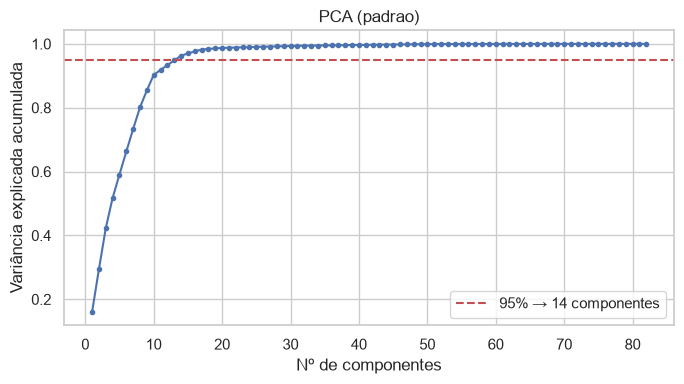

In [12]:
# Plotly: projeção PCA 2-D interativa (todas as positivas da amostra + negativas sorteadas).
def grafico_pca_2d_plotly(X_amostra, y_amostra, escalonador="padrao", n=10_000):
    
    pos = X_amostra.index[y_amostra.loc[X_amostra.index] == 1]
    neg = X_amostra.index[y_amostra.loc[X_amostra.index] == 0]
    idx = pos[: n // 2].union(pd.Index(np.random.default_rng(SEMENTE).choice(neg, min(n, len(neg)), replace=False)))
    comp = PCA(n_components=2, random_state=SEMENTE).fit_transform(
        construir_preprocessador(escalonador).fit_transform(X_amostra.loc[idx]))
    df_plot = pd.DataFrame({"PC1": comp[:, 0], "PC2": comp[:, 1], "classe": y_amostra.loc[idx].astype(str).values})
    px.scatter(df_plot, x="PC1", y="PC2", color="classe", opacity=0.6,
               title="Projeção PCA 2-D (0 = normal, 1 = lavagem)").show()

# Calcula a quantidade de componentes utilizando uma amostra de até 100 mil registros
N_PCA = grafico_variancia_pca(X_cv.sample(min(100_000, len(X_cv)), random_state=SEMENTE))
grafico_pca_2d_plotly(X_cv, y_cv)

# 6. Modelos

### 6.1 - Criação dos Modelos

In [14]:
# Retorna {nome: estimador/Pipeline}. A PCA (opcional) é aplicada somente à Regressão Logística.
def criar_modelos(escalonador="padrao", n_componentes_pca=None, semente=SEMENTE):
    passos_lr = [("preprocessador", construir_preprocessador(escalonador))]
    if n_componentes_pca:
        passos_lr.append(("pca", PCA(n_components=n_componentes_pca, random_state=semente)))
    passos_lr.append(("classificador", LogisticRegression(
        max_iter=1000, class_weight="balanced", random_state=semente)))
    # Modelos
    return {
        "Dummy": DummyClassifier(strategy="most_frequent"),
        "LogisticRegression": Pipeline(passos_lr),
        "RandomForest": Pipeline([
            ("preprocessador", construir_preprocessador(escalonador)),
            ("classificador", RandomForestClassifier(
                n_estimators=100, max_depth=20, min_samples_leaf=2,
                class_weight="balanced_subsample", random_state=semente, n_jobs=-1)),
        ]),
        "LightGBM": Pipeline([
            ("preprocessador", construir_preprocessador(escalonador)),
            ("classificador", LGBMClassifier(
                n_estimators=300, learning_rate=0.05, num_leaves=31, subsample=0.8, subsample_freq=1,
                colsample_bytree=0.8, class_weight="balanced", importance_type="gain",
                random_state=semente, n_jobs=-1, verbose=-1)),
        ]),
    }


modelos = criar_modelos("padrao")
list(modelos)

['Dummy', 'LogisticRegression', 'RandomForest', 'LightGBM']

### 6.2 - Métricas

In [ ]:
def calcular_metricas(y_real, y_pred, y_prob):
    return {
        "accuracy": accuracy_score(y_real, y_pred),
        "precision": precision_score(y_real, y_pred, zero_division=0),
        "recall": recall_score(y_real, y_pred, zero_division=0),
        "f1": f1_score(y_real, y_pred, zero_division=0),
        # Average Precision = área sob a curva PR
        "pr_auc": average_precision_score(y_real, y_prob),      
    }

### 6.3 - Previsão de Probabilidades

In [ ]:
def prever_proba(modelo, X, tamanho_lote=250_000):
    return np.concatenate([
        modelo.predict
    ])

### 6.4 - Treinamento do Modelo

In [17]:
def treinar_modelos(modelo, X_treino, y_treino, verbose=True):
    treinados, tempos = {}, {}
    for nome, modelo in modelos.items():
        t0 = time.perf_counter()
        treinados[nome] = clone(modelo).fit(X_treino, y_treino)
        tempos[nome] = time.perf_counter() - t0
        if verbose:
            print(f"[treino] {nome:<20s} {tempos[nome]:7.1f}s")
    return treinados, tempos

### 6.5 - Validação do Modelo

Como `X` está **ordenado no tempo**, o padrão é `KFold(shuffle=False)`: cada *fold* é um bloco contínuo do período
(embaralhar misturaria transações vizinhas entre treino e validação). Outras opções: `"kfold_embaralhado"` e `"estratificado"`
(`StratifiedKFold`, garante positivos em todos os folds).

In [ ]:
def obter_cv(tipo="kfold", n_splits=N_SPLITS, semente=SEMENTE):
    if tipo == "kfold":
        return KFold(n_splits=n_splits, shuffle=False)
    if tipo == "kfold_embaralhado":
        return KFold(n_splits=n_splits, shuffle=True, random_state=semente)
    if tipo == "estratificado":
        return StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=semente)
    raise ValueError("tipo inválido")


def validar_modelos(modelos, X, y, cv=None, limiar=0.5, verbose=True):
    # Validação cruzada. Retorna um DataFrame com uma linha por (modelo, fold).
    cv = cv or obter_cv()
    linhas = []
    for nome, modelo in modelos.items():
        t0 = time.perf_counter()
        for fold, (tr, va) in enumerate(cv.split(X, y), start=1):
            m = clone(modelo).fit(X.iloc[tr], y.iloc[tr])
            prob = prever_proba(m, X.iloc[va])
            linhas.append({"modelo": nome, "fold": fold, "positivas_fold": int(y.iloc[va].sum()),
                           **calcular_metricas(y.iloc[va], (prob >= limiar).astype(int), prob)})
        if verbose:
            print(f"[cv] {nome:<20s} {time.perf_counter() - t0:7.1f}s")
    return pd.DataFrame(linhas)


def resumo_cv(cv_df):
    agg = cv_df.drop(columns=["fold", "positivas_fold"]).groupby("modelo").agg(["mean", "std"])
    agg.columns = [f"{m}_{s}" for m, s in agg.columns]
    return agg.sort_values("pr_auc_mean", ascending=False)

### 6.6 - Avaliação do Modelo

In [ ]:
def avaliar_modelo(modelo, X, y, nome="modelo", limiar=0.5, mostrar_relatorio=True):
    # Avalia um modelo já treinado em (X, y).
    prob = prever_proba(modelo, X)
    pred = (prob >= limiar).astype(int)
    res = {"nome": nome, "limiar": limiar, "y_pred": pred, "y_prob": prob,
           "matriz_confusao": confusion_matrix(y, pred), **calcular_metricas(y, pred, prob)}
    if mostrar_relatorio:
        print(f"{'=' * 60}\n{nome}  (limiar = {limiar:.4f})\n{'=' * 60}")
        print(classification_report(y, pred, target_names=["normal", "lavagem"], zero_division=0, digits=4))
        print("Matriz de confusão:\n", res["matriz_confusao"], "\n")
    return res


def avaliar_modelos(treinados, X, y, limiares=None, mostrar_relatorio=True):
    limiares = limiares or {}
    return {n: avaliar_modelo(m, X, y, n, limiares.get(n, 0.5), mostrar_relatorio) for n, m in treinados.items()}

### 6.7 - Comparação dos Modelos

In [ ]:
def comparar_modelos(resultados, ordenar_por="pr_auc", tempos=None):
    cols = ["accuracy", "precision", "recall", "f1", "pr_auc"]
    tabela = pd.DataFrame({n: {c: r[c] for c in cols} for n, r in resultados.items()}).T
    if tempos:
        tabela["tempo_treino_s"] = pd.Series(tempos)
    return tabela.sort_values(ordenar_por, ascending=False)

### 6.8 - Escolha do Limiar

In [ ]:
def limiar_melhor_f1(y_real, y_prob):
    p, r, thr = precision_recall_curve(y_real, y_prob)
    f1 = 2 * p[:-1] * r[:-1] / np.clip(p[:-1] + r[:-1], 1e-12, None)
    i = int(np.argmax(f1))
    return float(thr[i]), float(f1[i])


def limiar_recall_minimo(y_real, y_prob, recall_min=0.80):
    # Maior precisão possível garantindo recall >= recall_min (típico em AML: não perder casos).
    p, r, thr = precision_recall_curve(y_real, y_prob)
    ok = np.where(r[:-1] >= recall_min)[0]
    if len(ok) == 0:
        return float(thr[0]), float(p[0])
    i = ok[np.argmax(p[ok])]
    return float(thr[i]), float(p[i])

### 6.9 - Gráficos 

**Redução dos Pontos da Curva**

In [ ]:
def _reduzir_curva(p, r, thr, n=1500):
    # Reduz o nº de pontos da curva (plotly com milhões de pontos fica pesado).
    idx = np.unique(np.linspace(0, len(thr) - 1, min(n, len(thr))).astype(int))
    return p[:-1][idx], r[:-1][idx], thr[idx]

#### Matplotlib

In [ ]:
def grafico_matrizes_confusao(resultados, y_real, normalizar=None):
    n = len(resultados)
    fig, axes = plt.subplots(1, n, figsize=(4.2 * n, 4))
    for ax, (nome, r) in zip(np.atleast_1d(axes), resultados.items()):
        ConfusionMatrixDisplay.from_predictions(
            y_real, r["y_pred"], ax=ax, cmap="Blues", colorbar=False, normalize=normalizar,
            display_labels=["normal", "lavagem"], values_format=".2f" if normalizar else "d")
        ax.set_title(f"{nome}\nF1={r['f1']:.3f} | Recall={r['recall']:.3f}")
        ax.grid(False)
    plt.tight_layout()
    plt.show()


def grafico_curvas_pr(resultados, y_real):
    fig, ax = plt.subplots(figsize=(7, 5))
    for nome, r in resultados.items():
        p, rc, _ = precision_recall_curve(y_real, r["y_prob"])
        ax.plot(rc, p, lw=2, label=f"{nome} (AP={r['pr_auc']:.4f})")
    ax.axhline(np.mean(y_real), color="gray", ls="--", label=f"Sem habilidade ({np.mean(y_real):.4f})")
    ax.set(xlabel="Recall", ylabel="Precisão", title="Curvas Precisão × Recall", xlim=(0, 1), ylim=(0, 1.02))
    ax.legend()
    plt.tight_layout()
    plt.show()


def grafico_limiar(y_real, y_prob, nome="modelo"):
    p, r, thr = precision_recall_curve(y_real, y_prob)
    f1 = 2 * p[:-1] * r[:-1] / np.clip(p[:-1] + r[:-1], 1e-12, None)
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(thr, p[:-1], label="Precisão")
    ax.plot(thr, r[:-1], label="Recall")
    ax.plot(thr, f1, label="F1", lw=2)
    ax.axvline(thr[np.argmax(f1)], color="k", ls=":", label=f"melhor F1 @ {thr[np.argmax(f1)]:.3f}")
    ax.set(xlabel="Limiar", title=f"Trade-off do limiar — {nome}")
    ax.legend()
    plt.tight_layout()
    plt.show()

#### Seaborn

In [ ]:
def grafico_heatmap_metricas(comparacao, titulo="Comparação dos modelos"):
    cols = [c for c in ["accuracy", "precision", "recall", "f1", "pr_auc"] if c in comparacao]
    fig, ax = plt.subplots(figsize=(7, 0.8 * len(comparacao) + 1.5))
    sns.heatmap(comparacao[cols], annot=True, fmt=".3f", cmap="YlGnBu", vmin=0, vmax=1, ax=ax)
    ax.set_title(titulo)
    plt.tight_layout()
    plt.show()


def grafico_boxplot_cv(cv_df, metricas=("precision", "recall", "f1", "pr_auc")):
    fig, axes = plt.subplots(1, len(metricas), figsize=(4.2 * len(metricas), 4))
    for ax, m in zip(np.atleast_1d(axes), metricas):
        sns.boxplot(data=cv_df, x="modelo", y=m, ax=ax, palette="Set2")
        sns.stripplot(data=cv_df, x="modelo", y=m, ax=ax, color="k", size=3, alpha=0.6)
        ax.set_title(m)
        ax.set_xlabel("")
        ax.tick_params(axis="x", rotation=30)
    plt.suptitle(f"Validação cruzada KFold ({cv_df['fold'].nunique()} folds)", y=1.02)
    plt.tight_layout()
    plt.show()

#### Plotly

In [ ]:
def plotly_curvas_pr(resultados, y_real):
    fig = go.Figure()
    for nome, r in resultados.items():
        p, rc, thr = precision_recall_curve(y_real, r["y_prob"])
        p, rc, thr = _reduzir_curva(p, rc, thr)
        fig.add_trace(go.Scatter(x=rc, y=p, mode="lines", name=f"{nome} (AP={r['pr_auc']:.4f})", customdata=thr,
                                 hovertemplate="recall=%{x:.3f}<br>precisão=%{y:.3f}<br>limiar=%{customdata:.3f}<extra></extra>"))
    fig.add_hline(y=float(np.mean(y_real)), line_dash="dash", line_color="gray", annotation_text="sem habilidade")
    fig.update_layout(title="Curvas Precisão × Recall (interativo)", xaxis_title="Recall",
                      yaxis_title="Precisão", template="plotly_white", height=520)
    fig.show()


def plotly_barras_metricas(comparacao):
    longo = (comparacao[["accuracy", "precision", "recall", "f1", "pr_auc"]].reset_index()
             .rename(columns={"index": "modelo"}).melt("modelo", var_name="métrica", value_name="valor"))
    px.bar(longo, x="métrica", y="valor", color="modelo", barmode="group", text_auto=".3f",
           title="Comparação dos modelos").update_layout(template="plotly_white", height=500).show()


def plotly_boxplot_cv(cv_df, metrica="pr_auc"):
    px.box(cv_df, x="modelo", y=metrica, color="modelo", points="all", hover_data=["fold", "positivas_fold"],
           title=f"Validação cruzada — {metrica}").update_layout(template="plotly_white", showlegend=False).show()


def plotly_limiar(y_real, y_prob, nome="modelo"):
    p, r, thr = precision_recall_curve(y_real, y_prob)
    f1 = 2 * p[:-1] * r[:-1] / np.clip(p[:-1] + r[:-1], 1e-12, None)
    pp, rr, tt = _reduzir_curva(p, r, thr)
    ff = 2 * pp * rr / np.clip(pp + rr, 1e-12, None)
    fig = go.Figure()
    for rotulo, vals in [("Precisão", pp), ("Recall", rr), ("F1", ff)]:
        fig.add_trace(go.Scatter(x=tt, y=vals, mode="lines", name=rotulo))
    fig.add_vline(x=float(thr[np.argmax(f1)]), line_dash="dot", annotation_text="melhor F1")
    fig.update_layout(title=f"Trade-off do limiar — {nome}", xaxis_title="Limiar", template="plotly_white")
    fig.show()


def importancia_atributos(modelo_treinado):
    clf = modelo_treinado.named_steps["classificador"]
    nomes = [n.split("__", 1)[-1] for n in modelo_treinado.named_steps["preprocessador"].get_feature_names_out()]
    if hasattr(clf, "feature_importances_"):
        imp = clf.feature_importances_
    elif hasattr(clf, "coef_") and "pca" not in modelo_treinado.named_steps:
        imp = np.abs(clf.coef_[0])
    else:
        raise ValueError("Importância indisponível (ex.: PCA aplicada).")
    s = pd.Series(imp, index=nomes).sort_values(ascending=False)
    return s / s.sum()


def plotly_importancia(modelo_treinado, nome="modelo", top=20):
    imp = importancia_atributos(modelo_treinado).head(top).sort_values()
    px.bar(imp, x=imp.values, y=imp.index, orientation="h", labels={"x": "importância relativa", "y": ""},
           title=f"Top {top} atributos — {nome}").update_layout(template="plotly_white", height=600).show()

# 7. Experimentos

### 7.1 - Escalonadores e PCA na Regressão Logística

Validação cruzada na amostra `X_cv`.

In [ ]:
cv = obter_cv("kfold", N_SPLITS)

variantes_lr = {
    "LR | padrão": criar_modelos("padrao")["LogisticRegression"],
    "LR | minmax": criar_modelos("minmax")["LogisticRegression"],
    f"LR | padrão + PCA({N_PCA})": criar_modelos("padrao", N_PCA)["LogisticRegression"],
    f"LR | minmax + PCA({N_PCA})": criar_modelos("minmax", N_PCA)["LogisticRegression"],
}
cv_escalonadores = validar_modelos(variantes_lr, X_cv, y_cv, cv)
resumo_cv(cv_escalonadores)[["precision_mean", "recall_mean", "f1_mean", "pr_auc_mean", "pr_auc_std"]]

In [ ]:
grafico_boxplot_cv(cv_escalonadores, metricas=("recall", "f1", "pr_auc"))

#### 7.2 - Validação Cruzada KFolds nos Modelos

In [ ]:
ESCALONADOR = "padrao"          # troque por "minmax" se o experimento acima indicar
modelos = criar_modelos(ESCALONADOR)

cv_df = validar_modelos(modelos, X_cv, y_cv, cv)
display(cv_df.groupby("modelo")["positivas_fold"].sum().rename("positivas_total"))
resumo_cv(cv_df)[["accuracy_mean", "precision_mean", "recall_mean", "f1_mean", "pr_auc_mean", "pr_auc_std"]]

In [ ]:
grafico_boxplot_cv(cv_df)
plotly_boxplot_cv(cv_df, "pr_auc")

#### 7.4 - Treinamento Final e Avaliação na Validação

In [ ]:
treinados, tempos = treinar_modelos(modelos, X_train_execucao, y_train_execucao)

res_val = avaliar_modelos(treinados, X_val, y_val)
comp_val = comparar_modelos(res_val, tempos=tempos)
comp_val.round(4)

In [ ]:
grafico_matrizes_confusao(res_val, y_val)
grafico_curvas_pr(res_val, y_val)
plotly_curvas_pr(res_val, y_val)
grafico_heatmap_metricas(comp_val, "Validação (limiar 0,5)")
plotly_barras_metricas(comp_val)

#### 7.4 - Escolha do Limiar na Validação e Resultado Final do Teste

In [ ]:
nomes_modelos = ["LogisticRegression", "RandomForest", "LightGBM"]
limiares = {}
for nome in nomes_modelos:
    thr, f1_val = limiar_melhor_f1(y_val, res_val[nome]["y_prob"])
    thr_r, prec_r = limiar_recall_minimo(y_val, res_val[nome]["y_prob"], 0.80)
    limiares[nome] = thr
    print(f"{nome:<20s} melhor F1 @ {thr:.4f} (F1={f1_val:.3f}) | recall≥80% @ {thr_r:.4f} (precisão={prec_r:.3f})")

res_teste = avaliar_modelos({n: treinados[n] for n in nomes_modelos}, X_test, y_test, limiares=limiares, mostrar_relatorio=False)
res_teste["Dummy"] = avaliar_modelo(treinados["Dummy"], X_test, y_test, "Dummy", 0.5, mostrar_relatorio=False)
comp_teste = comparar_modelos(res_teste)
print("\nResultado final no TESTE (limiar escolhido na validação):")
comp_teste.round(4)

In [ ]:
melhor = comp_teste.drop(index="Dummy")["pr_auc"].idxmax()
print("Melhor modelo (PR-AUC no teste):", melhor)

grafico_limiar(y_val, res_val[melhor]["y_prob"], melhor)
plotly_limiar(y_val, res_val[melhor]["y_prob"], melhor)
grafico_matrizes_confusao(res_teste, y_test)
grafico_curvas_pr(res_teste, y_test)
plotly_curvas_pr(res_teste, y_test)
grafico_heatmap_metricas(comp_teste, "Teste (limiar da validação)")
print(classification_report(y_test, res_teste[melhor]["y_pred"], target_names=["normal", "lavagem"], digits=4))

#### 7.5 - Importância dos Atributos e Salvamento do Melhor Modelo

In [ ]:
for n in ["RandomForest", "LightGBM"]:
    plotly_importancia(treinados[n], n, top=15)

imp_lr = importancia_atributos(treinados["LogisticRegression"]).head(15).sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
imp_lr.plot.barh(ax=ax, color="#4C72B0")
ax.set_title("Top 15 atributos — Regressão Logística (|coeficiente|)")
plt.tight_layout()
plt.show()

In [ ]:
artefato = {"modelo": treinados[melhor], "limiar": limiares[melhor],
            "colunas_numericas": colunas_numericas, "colunas_categoricas": colunas_categoricas}
joblib.dump(artefato, "aml_melhor_modelo.joblib")
print(f"Modelo '{melhor}' salvo (limiar = {limiares[melhor]:.4f}) → aml_melhor_modelo.joblib")